#### Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from extensions.experiments import Sweep, generate_run, judge_run

RUN = False
RUNS = [('Qwen/Qwen3-4B', 'football'), ('Qwen/Qwen3-4B', 'dog'), ('Qwen/Qwen3-8B', 'dog')]
configs = {
    f"{model.split('/')[-1]}, {concept}": Sweep(
        '01_qwen3_model_ablation', model_name=model, concept=concept, trials=100,
        lambdas=(0.5, 1., 1.5, 2., 2.5, 3., 3.5, 4.), r_values=(0.1, 1., 10.), last_n=(None,),
        operators=('Identity', 'Random', 'Mean Jacobian'), drift_weights=(0.,),
        generation_batch=100, judge_batch=128, record_layer_actuation=True,
        run_name=f'{concept}_r_sweep_n100')
    for model, concept in RUNS
}
config = next(iter(configs.values()))
COLORS = {'Identity': 'tab:blue', 'Random': 'tab:orange', 'Mean Jacobian': 'tab:green'}

#### Generate, judge, and load

In [2]:
if RUN:
    for run_config in configs.values():
        generate_run(run_config)
        judge_run(run_config)

def load(filename):
    return pd.concat([pd.read_csv(c.run_dir / filename).assign(run=run) for run, c in configs.items()],
                     ignore_index=True)

summary = load('summary.csv')
actuation = load('layer_actuation_summary.csv')

#### Coherence versus concept

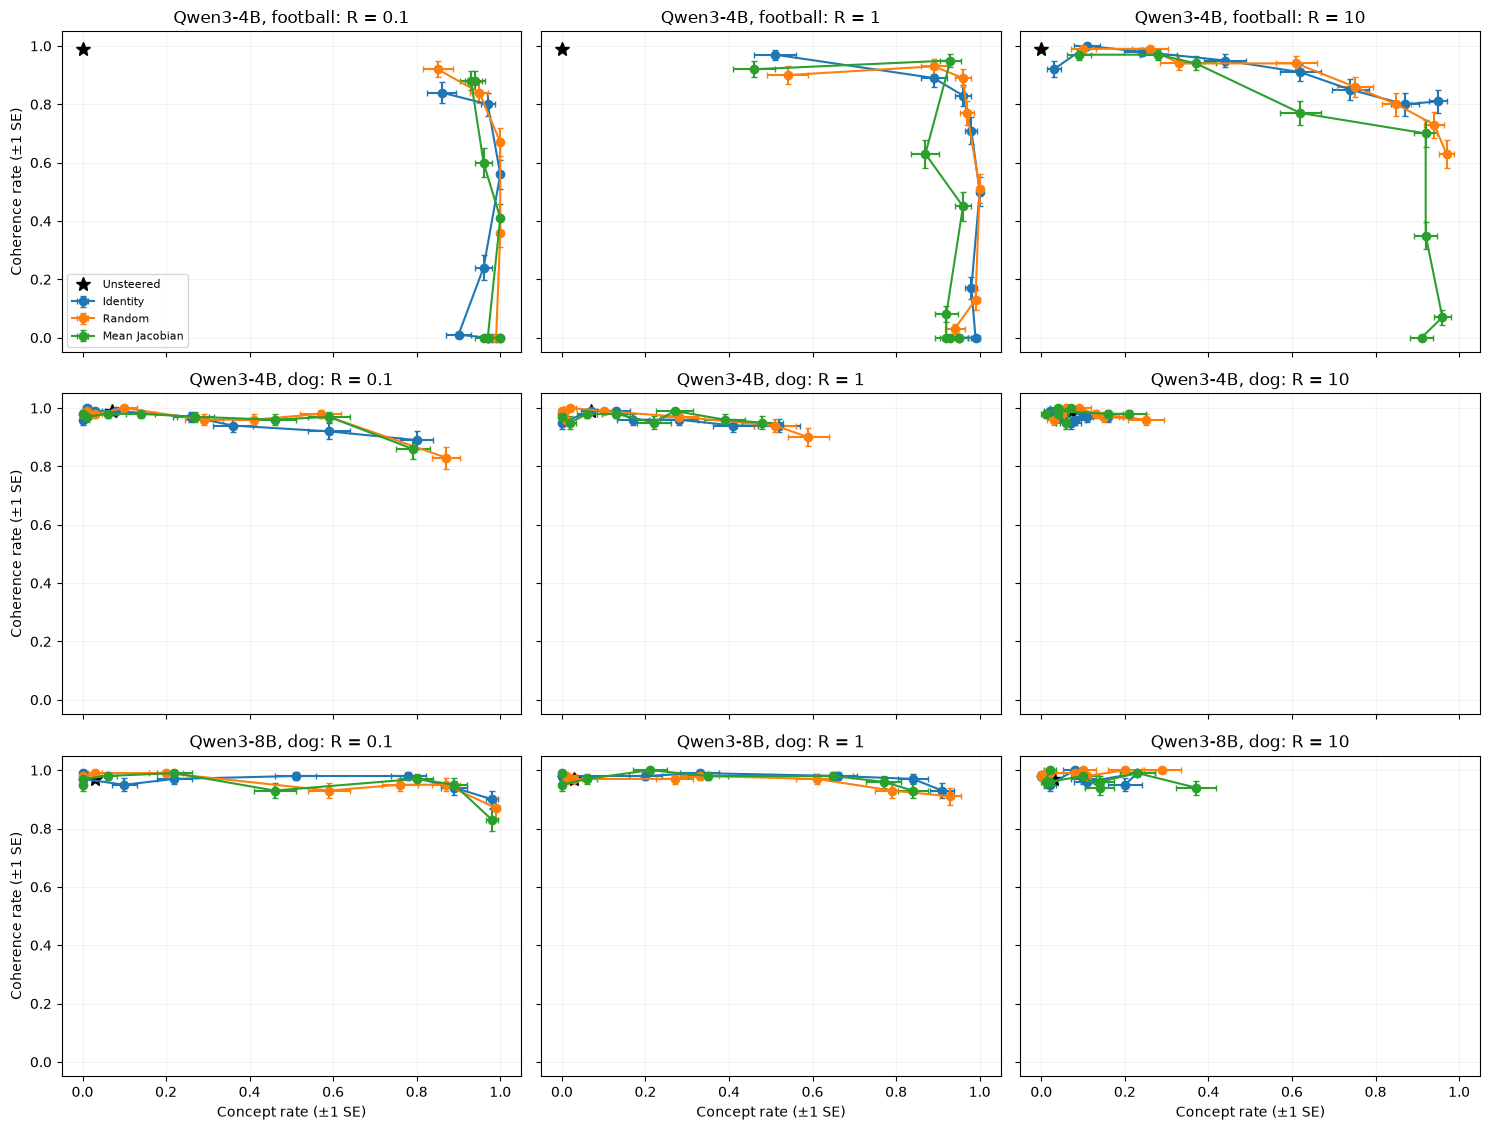

In [3]:
fig, axes = plt.subplots(len(configs), len(config.r_values), figsize=(15, 3.8 * len(configs)),
                         sharex=True, sharey=True, squeeze=False)
for row, run in zip(axes, configs):
    data = summary.loc[summary.run.eq(run)]
    baseline = data.loc[data.operator.eq('Unsteered')]
    for ax, R in zip(row, config.r_values):
        for name in config.operators:
            curve = data.loc[data.R.eq(R) & data.operator.eq(name)].sort_values('lambda')
            ax.errorbar(curve.concept, curve.coherent, xerr=curve.concept_se, yerr=curve.coherent_se,
                        marker='o', capsize=2, color=COLORS[name], label=name)
        ax.plot(baseline.concept, baseline.coherent, 'k*', ms=10, label='Unsteered')
        ax.set(title=f'{run}: R = {R:g}', xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
        ax.grid(alpha=0.15)
for ax in axes[-1]:
    ax.set_xlabel('Concept rate (±1 SE)')
for ax in axes[:, 0]:
    ax.set_ylabel('Coherence rate (±1 SE)')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

#### Push energy by layer

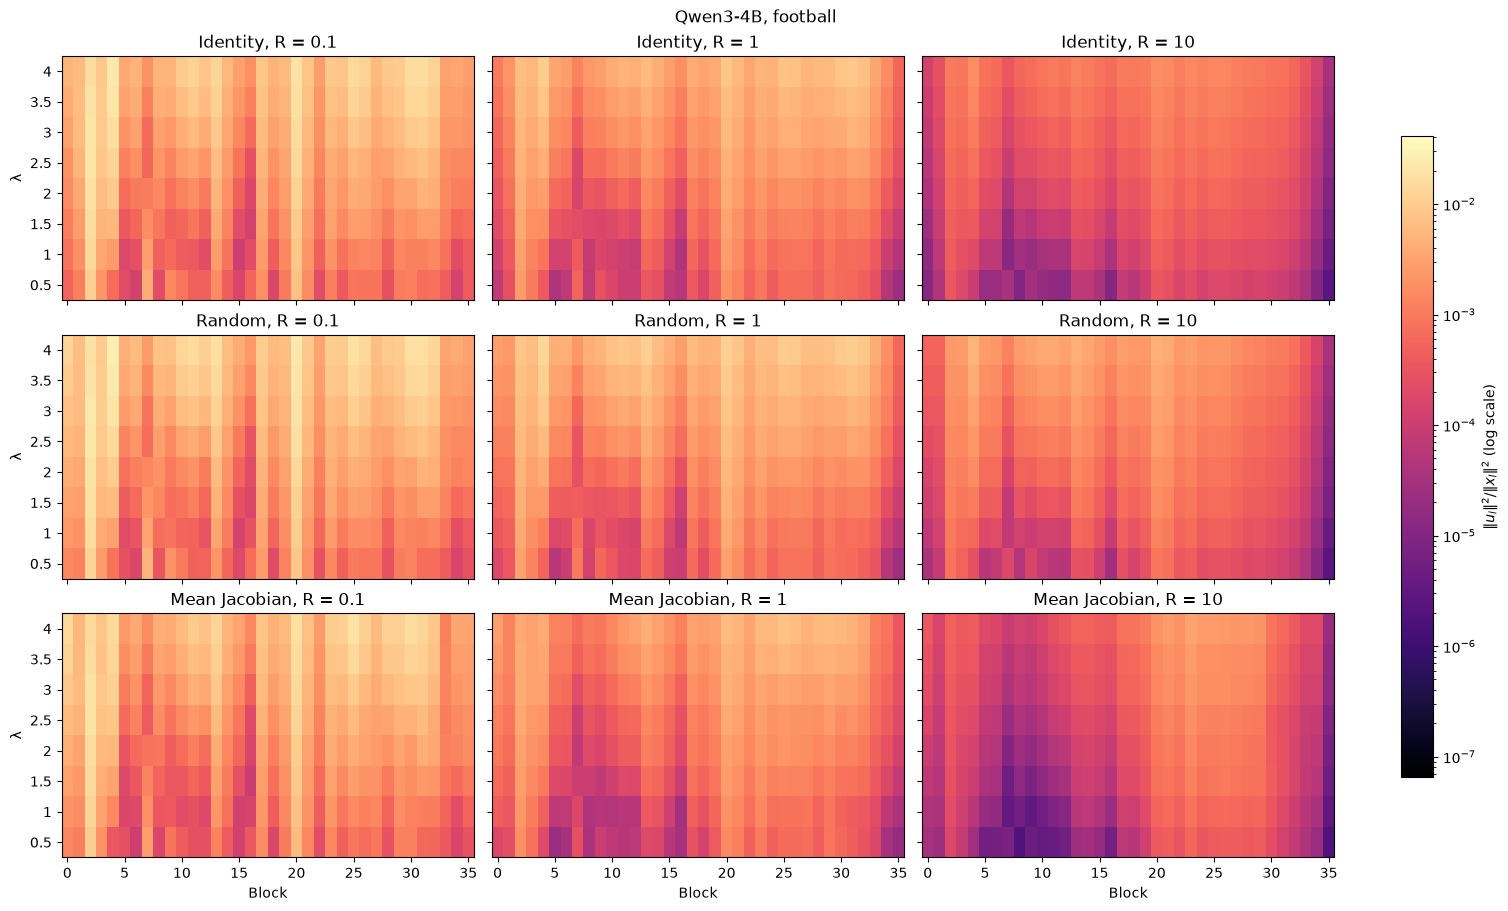

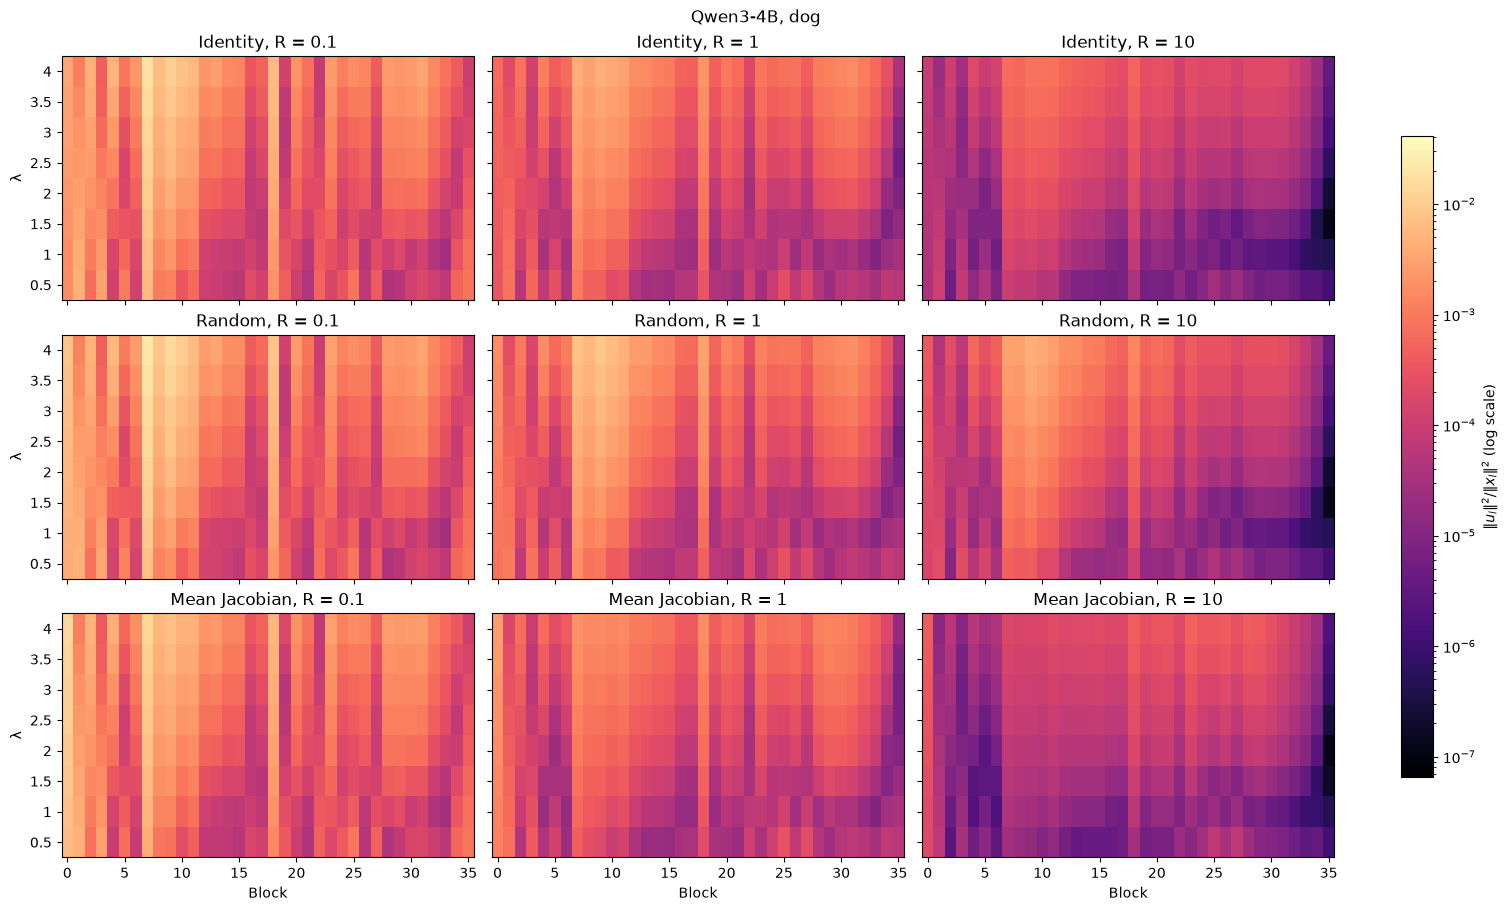

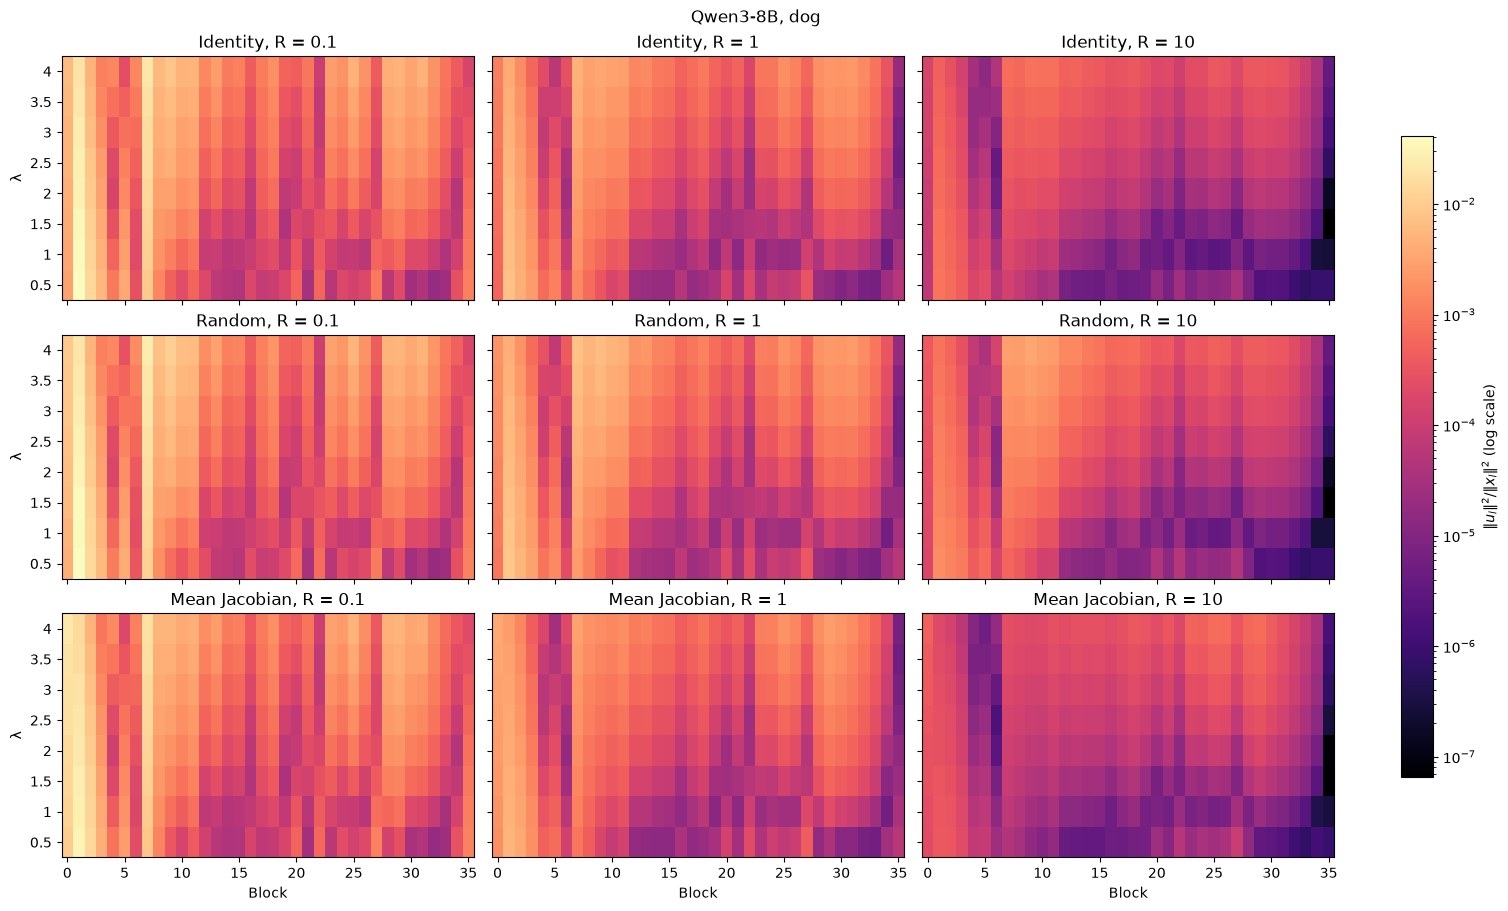

In [4]:
positive = actuation.push_energy[actuation.push_energy.gt(0)]
norm = LogNorm(positive.min(), positive.max())
cmap = plt.get_cmap('magma').copy()
cmap.set_bad('lightgray')
for run, run_config in configs.items():
    data = actuation.loc[actuation.run.eq(run)]
    fig, axes = plt.subplots(len(config.operators), len(config.r_values), figsize=(15, 9),
                             sharex=True, sharey=True, layout='constrained')
    for row, name in zip(axes, config.operators):
        for ax, R in zip(row, config.r_values):
            values = data.loc[data.operator.eq(name) & data.R.eq(R)].pivot(
                index='lambda', columns='layer', values='push_energy')
            image = ax.imshow(np.ma.masked_less_equal(values.to_numpy(), 0), origin='lower', aspect='auto',
                              cmap=cmap, norm=norm, interpolation='nearest')
            ax.set_title(f'{name}, R = {R:g}')
            ax.set_yticks(range(len(values)), labels=[f'{value:g}' for value in values.index])
    for ax in axes[-1]:
        ax.set_xlabel('Block')
    for ax in axes[:, 0]:
        ax.set_ylabel('λ')
    fig.colorbar(image, ax=axes, label=r'$\|u_l\|^2 / \|x_l\|^2$ (log scale)', shrink=0.8)
    fig.suptitle(run)
    fig.savefig(run_config.run_dir / f'layer_actuation_{run_config.concept}.png', dpi=150)
    plt.show()